In [1]:
import pandas as pd
import math

In [2]:
retail_df = pd.read_excel('./Online_Retail.xlsx')
display(retail_df.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
!pip install openpyxl

In [7]:
print(retail_df.info())

<class 'pandas.DataFrame'>
Index: 397884 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    397884 non-null  object        
 1   StockCode    397884 non-null  object        
 2   Description  397884 non-null  object        
 3   Quantity     397884 non-null  int64         
 4   InvoiceDate  397884 non-null  datetime64[us]
 5   UnitPrice    397884 non-null  float64       
 6   CustomerID   397884 non-null  float64       
 7   Country      397884 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.4+ MB
None


In [8]:
retail_df = retail_df[retail_df['Quantity'] > 0] # 수량 >= 1
retail_df = retail_df[retail_df['UnitPrice'] > 0] # 단가 >= 1
retail_df = retail_df[retail_df['CustomerID'].notnull()] # 결측치 제거

retail_df['CustomerID'] = retail_df['CustomerID'].astype(int) # 정수형으로 변환

In [9]:
print(retail_df.info())
print(retail_df.isnull().sum())
print(retail_df.shape)

<class 'pandas.DataFrame'>
Index: 397884 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    397884 non-null  object        
 1   StockCode    397884 non-null  object        
 2   Description  397884 non-null  object        
 3   Quantity     397884 non-null  int64         
 4   InvoiceDate  397884 non-null  datetime64[us]
 5   UnitPrice    397884 non-null  float64       
 6   CustomerID   397884 non-null  int64         
 7   Country      397884 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), object(3), str(1)
memory usage: 32.4+ MB
None
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64
(397884, 8)


In [10]:
retail_df.drop_duplicates(inplace=True) # 중복 레코드 제거
print(retail_df.shape)

(392692, 8)


In [12]:
pd.DataFrame([{'Product': len(retail_df['StockCode'].value_counts()),
                              'Transaction': len(retail_df['InvoiceNo'].value_counts()),
                              'Customer': len(retail_df['CustomerID'].value_counts())}],
                              columns = ['Product', 'Transaction', 'Customer'],
                              index = ['counts'])

,Product,Transaction,Customer
counts,3665,18532,4338


In [14]:
print(retail_df['Country'].value_counts()) # 국가별 주문건수

Country
United Kingdom          349203
Germany                   9025
France                    8326
EIRE                      7226
Spain                     2479
Netherlands               2359
Belgium                   2031
Switzerland               1841
Portugal                  1453
Australia                 1181
Norway                    1071
Italy                      758
Channel Islands            747
Finland                    685
Cyprus                     603
Sweden                     450
Austria                    398
Denmark                    380
Poland                     330
Japan                      321
Israel                     245
Unspecified                241
Singapore                  222
Iceland                    182
USA                        179
Canada                     151
Greece                     145
Malta                      112
United Arab Emirates        68
European Community          60
RSA                         57
Lebanon                     45


In [15]:
retail_df['SaleAmount'] = retail_df['UnitPrice'] * retail_df['Quantity'] # 페어를 곱해, 주문 금액 컬럼 만듦
print(retail_df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  SaleAmount  
0 2010-12-01 08:26:00       2.55       17850  United Kingdom       15.30  
1 2010-12-01 08:26:00       3.39       17850  United Kingdom       20.34  
2 2010-12-01 08:26:00       2.75       17850  United Kingdom       22.00  
3 2010-12-01 08:26:00       3.39       17850  United Kingdom       20.34  
4 2010-12-01 08:26:00       3.39       17850  United Kingdom       20.34  


In [17]:
aggregations = {
    'InvoiceNo': 'count',
    'SaleAmount': 'sum',
    'InvoiceDate': 'max'
}
customer_df = retail_df.groupby('CustomerID').agg(aggregations)
customer_df = customer_df.reset_index() # 인덱스 초기화
print(customer_df.head())

   CustomerID  InvoiceNo  SaleAmount         InvoiceDate
0       12346          1    77183.60 2011-01-18 10:01:00
1       12347        182     4310.00 2011-12-07 15:52:00
2       12348         31     1797.24 2011-09-25 13:13:00
3       12349         73     1757.55 2011-11-21 09:51:00
4       12350         17      334.40 2011-02-02 16:01:00


In [18]:
customer_df = customer_df.rename(columns = {'InvoiceNo': 'Freq',
                                            'InvoiceDate': 'ElapsedDays'})
print(customer_df.head())

   CustomerID  Freq  SaleAmount         ElapsedDays
0       12346     1    77183.60 2011-01-18 10:01:00
1       12347   182     4310.00 2011-12-07 15:52:00
2       12348    31     1797.24 2011-09-25 13:13:00
3       12349    73     1757.55 2011-11-21 09:51:00
4       12350    17      334.40 2011-02-02 16:01:00


In [19]:
import datetime

customer_df['ElapsedDays'] = datetime.datetime(2011, 12, 10) - customer_df['ElapsedDays']
print(customer_df.head())

   CustomerID  Freq  SaleAmount       ElapsedDays
0       12346     1    77183.60 325 days 13:59:00
1       12347   182     4310.00   2 days 08:08:00
2       12348    31     1797.24  75 days 10:47:00
3       12349    73     1757.55  18 days 14:09:00
4       12350    17      334.40 310 days 07:59:00


In [20]:
customer_df['ElapsedDays'] = customer_df['ElapsedDays'].apply(lambda x: x.days + 1)
print(customer_df.head())

   CustomerID  Freq  SaleAmount  ElapsedDays
0       12346     1    77183.60          326
1       12347   182     4310.00            3
2       12348    31     1797.24           76
3       12349    73     1757.55           19
4       12350    17      334.40          311


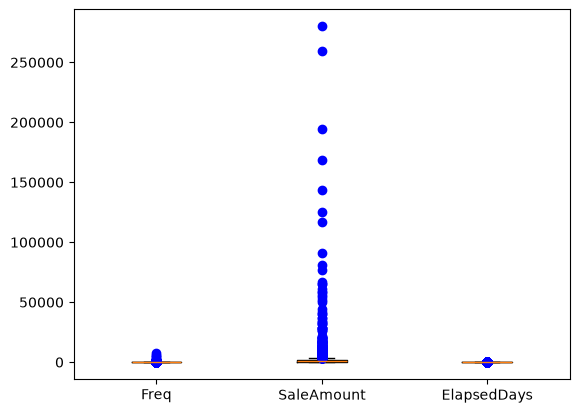

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots()
ax.boxplot([customer_df['Freq'], customer_df['SaleAmount'], customer_df['ElapsedDays']], sym = 'bo') # 파란 원형
plt.xticks([1, 2, 3], ['Freq', 'SaleAmount', 'ElapsedDays'])
plt.show()

In [22]:
import numpy as np

# scale down
customer_df['Freq_log'] = np.log1p(customer_df['Freq'])
customer_df['SaleAmount_log'] = np.log1p(customer_df['SaleAmount'])
customer_df['ElapsedDays_log'] = np.log1p(customer_df['ElapsedDays'])
print(customer_df.head())

   CustomerID  Freq  SaleAmount  ElapsedDays  Freq_log  SaleAmount_log  \
0       12346     1    77183.60          326  0.693147       11.253955   
1       12347   182     4310.00            3  5.209486        8.368925   
2       12348    31     1797.24           76  3.465736        7.494564   
3       12349    73     1757.55           19  4.304065        7.472245   
4       12350    17      334.40          311  2.890372        5.815324   

   ElapsedDays_log  
0         5.789960  
1         1.386294  
2         4.343805  
3         2.995732  
4         5.743003  


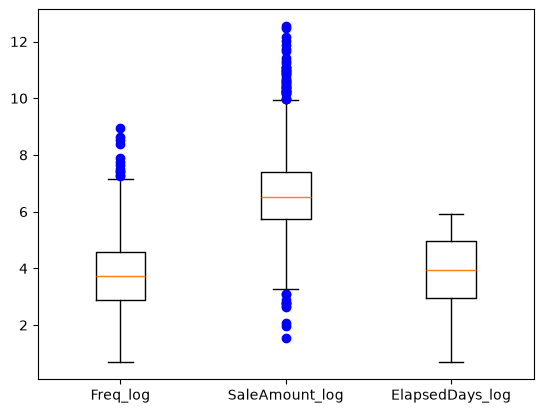

In [23]:
fig, ax = plt.subplots()
ax.boxplot([customer_df['Freq_log'], customer_df['SaleAmount_log'], customer_df['ElapsedDays_log']], sym = 'bo')
plt.xticks([1, 2, 3], ['Freq_log', 'SaleAmount_log', 'ElapsedDays_log'])
plt.show()

In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

X_features = customer_df[['Freq_log', 'SaleAmount_log', 'ElapsedDays_log']].values

In [25]:
from sklearn.preprocessing import StandardScaler
X_features_scaled = StandardScaler().fit_transform(X_features)
print(X_features_scaled)

[[-2.43820181  3.7077163   1.47888429]
 [ 1.18898578  1.41490344 -1.89064214]
 [-0.21146474  0.72002428  0.37233877]
 ...
 [-0.9349095  -1.11333158 -1.27014755]
 [ 2.29130702  0.82281217 -1.71990073]
 [ 0.42858139  0.73752572 -0.05585907]]


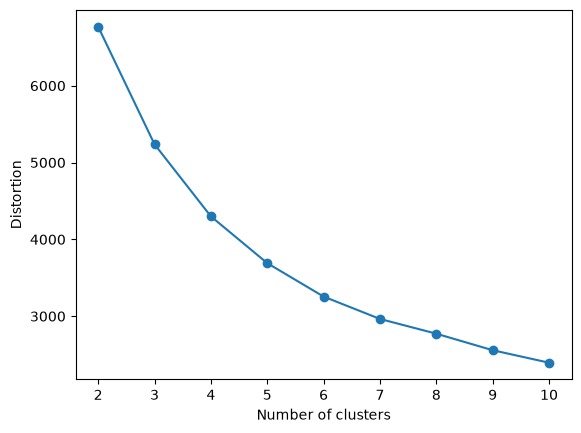

In [26]:
distortions = []

for i in range(2, 11):
    kmeans_i = KMeans(n_clusters = i, random_state = 0) # 모델 생성
    kmeans_i.fit(X_features_scaled)
    distortions.append(kmeans_i.inertia_) # 왜곡 값

# k에 따른 왜곡값 시각화
plt.plot(range(2,11), distortions, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Distortion')
plt.show()

In [28]:
kmeans = KMeans(n_clusters = 3, random_state = 0)
Y_labels = kmeans.fit_predict(X_features_scaled)

customer_df['ClusterLabel'] = Y_labels
print(customer_df.head())

   CustomerID  Freq  SaleAmount  ElapsedDays  Freq_log  SaleAmount_log  \
0       12346     1    77183.60          326  0.693147       11.253955   
1       12347   182     4310.00            3  5.209486        8.368925   
2       12348    31     1797.24           76  3.465736        7.494564   
3       12349    73     1757.55           19  4.304065        7.472245   
4       12350    17      334.40          311  2.890372        5.815324   

   ElapsedDays_log  ClusterLabel  
0         5.789960             2  
1         1.386294             1  
2         4.343805             2  
3         2.995732             2  
4         5.743003             0  


In [32]:
from matplotlib import cm

def silhouetteViz(n_cluster, X_features):
    kmeans = KMeans(n_clusters = n_cluster, random_state = 0)
    Y_labels = kmeans.fit_predict(X_features) # 학습 + 예측

    silhouette_values = silhouette_samples(X_features, Y_labels, metric = 'euclidean')

    y_ax_lower, y_ax_upper = 0, 0
    y_ticks = []

    for c in range(n_cluster):
        c_silhouettes = silhouette_values[Y_labels == c]
        c_silhouettes.sort()
        y_ax_upper += len(c_silhouettes) # 상한값 지정
        color = cm.jet(float(c) / n_cluster)
        plt.barh(range(y_ax_lower, y_ax_upper), c_silhouettes, height = 1.0, edgecolor = 'none', color = color)
        y_ticks.append((y_ax_lower + y_ax_upper) / 2)
        y_ax_lower += len(c_silhouettes)

    silhouette_avg = np.mean(silhouette_values) # 평균
    plt.axvline(silhouette_avg, color = 'red', linestyle = '--') # 점선
    plt.title('Number of Cluster : ' + str(n_cluster) + '\n' + 'Silhouette Score : ' + str(round(silhouette_avg, 3)))
    plt.yticks(y_ticks, range(n_cluster))
    plt.xticks([0, 0.2, 0.4, 0.6, 0.8, 1])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.tight_layout()
    plt.show()

In [30]:
def clusterScatter(n_cluster, X_features):
    c_colors = []
    kmeans = KMeans(n_clusters = n_cluster, random_state = 0)
    Y_labels = kmeans.fit_predict(X_features)

    for i in range(n_cluster):
        c_color = cm.jet(float(i) / n_cluster)
        c_colors.append(c_color)
        plt.scatter(X_features[Y_labels == i, 0], X_features[Y_labels == i, 1], marker = 'o', color = c_color, edgecolor = 'black', s = 50, label = 'cluster' + str(i))

    for i in range(n_cluster):
        plt.scatter(kmeans.cluster_centers_[i,0], kmeans.cluster_centers_[i,1], marker = '^', color=c_colors[i], edgecolor = 'w', s = 200)

    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.show()

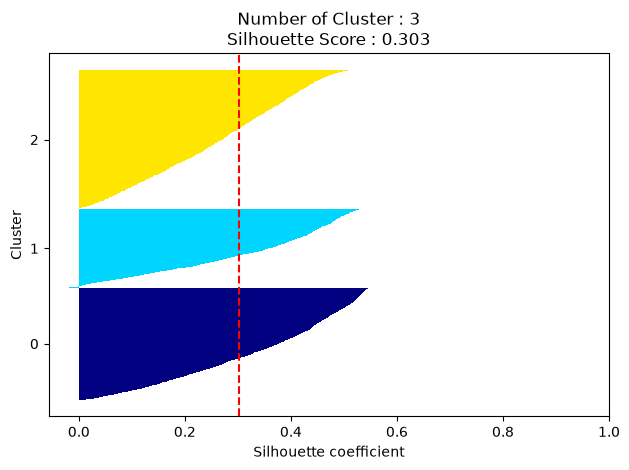

In [33]:
silhouetteViz(3, X_features_scaled)

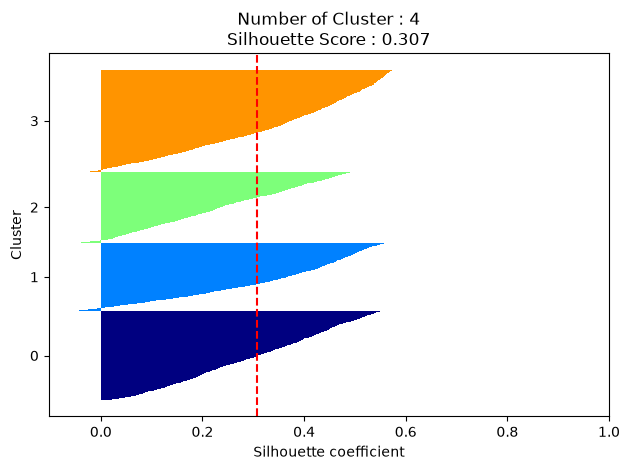

In [34]:
silhouetteViz(4, X_features_scaled)

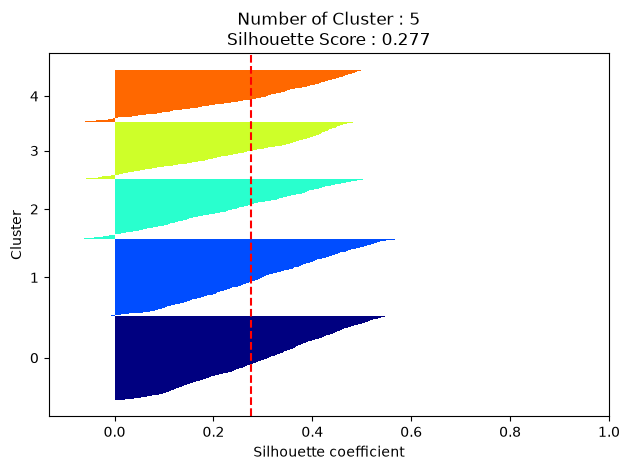

In [35]:
silhouetteViz(5, X_features_scaled)

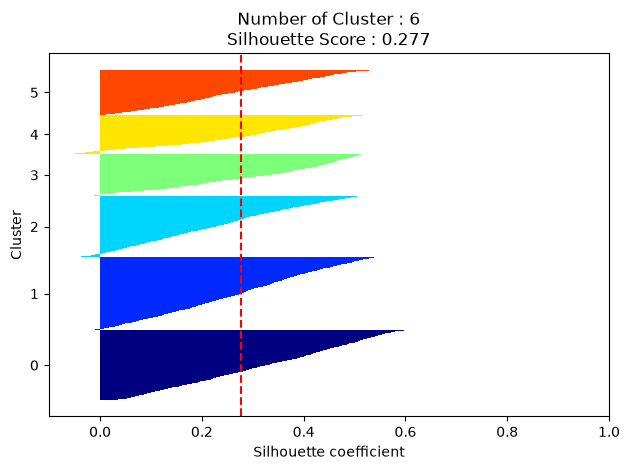

In [36]:
silhouetteViz(6, X_features_scaled)

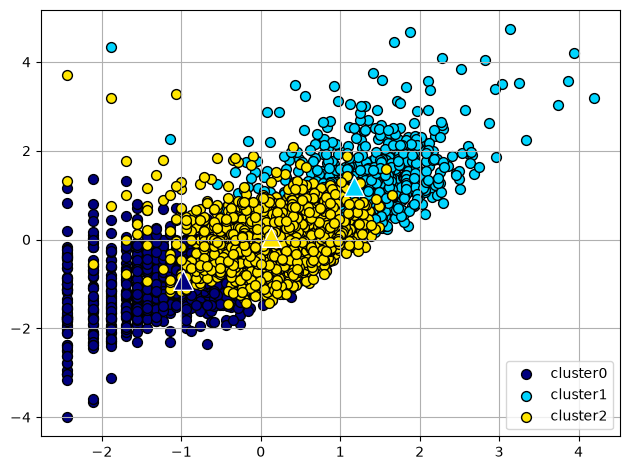

In [37]:
clusterScatter(3, X_features_scaled)

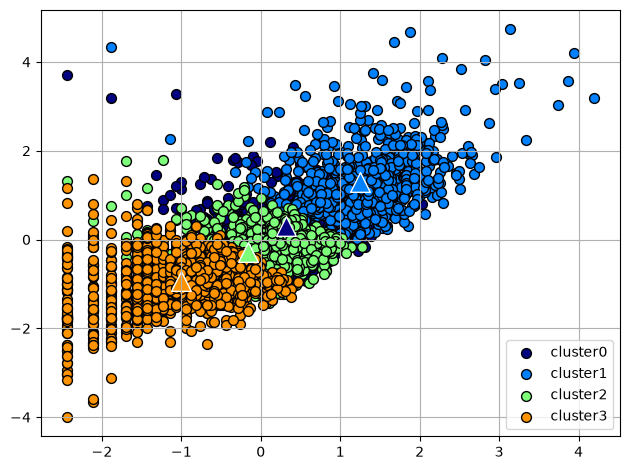

In [39]:
clusterScatter(4, X_features_scaled)

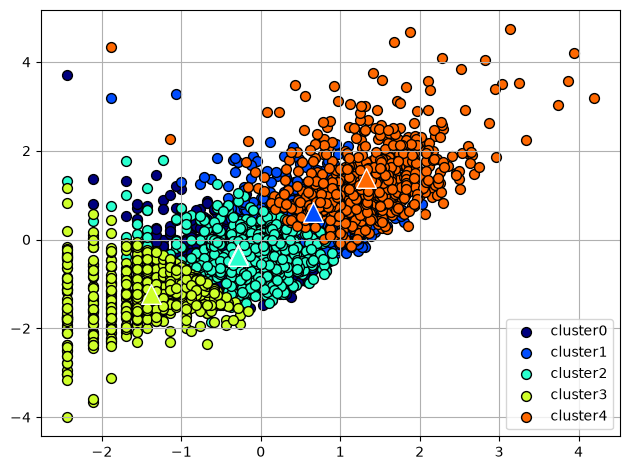

In [40]:
clusterScatter(5, X_features_scaled)

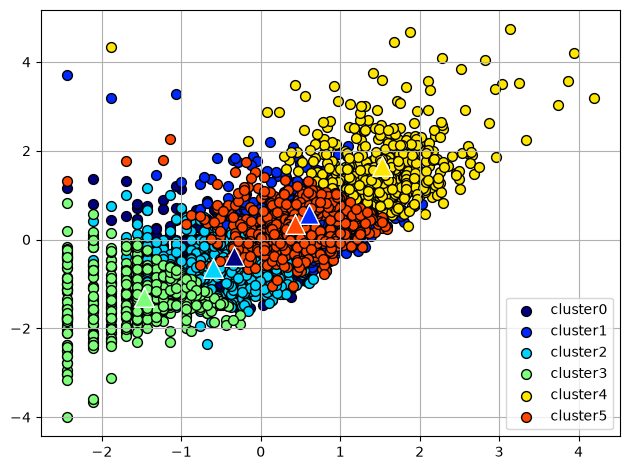

In [41]:
clusterScatter(6, X_features_scaled)

In [44]:
best_cluster = 4
kmeans = KMeans(n_clusters = best_cluster, random_state = 0)
Y_labels = kmeans.fit_predict(X_features_scaled)

customer_df['ClusterLabel'] = Y_labels
customer_df.head()

customer_df.to_csv('./Online_Retail_Customer_Cluster.csv') 

In [46]:
customer_df.groupby('ClusterLabel')['CustomerID'].count()

ClusterLabel
0    1167
1     900
2     931
3    1340
Name: CustomerID, dtype: int64

In [47]:
customer_cluster_df = customer_df.drop(['Freq_log', 'SaleAmount_log', 'ElapsedDays_log'], axis = 1, inplace = False)

#주문 1회당 평균 구매금액: SaleAmountAvg
customer_cluster_df['SaleAmountAvg'] = customer_cluster_df['SaleAmount']/customer_cluster_df['Freq']
customer_cluster_df.head()

customer_cluster_df.drop(['CustomerID'], axis = 1, inplace = False).groupby('ClusterLabel').mean()

,Freq,SaleAmount,ElapsedDays,SaleAmountAvg
ClusterLabel,,,,
0,74.443873,1453.809907,106.652956,106.760512
1,275.008889,6901.516111,14.833333,94.322099
2,41.978518,643.460173,20.473684,31.243547
3,14.347761,283.721501,184.191791,43.337452


In [49]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np
def clusterScatter(n_cluster, X_features):
    c_colors = []
    kmeans = KMeans(n_clusters = n_cluster, random_state = 0)
    Y_labels = kmeans.fit_predict(X_features)
    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(projection='3d')
    for i in range(n_cluster):
        c_color = cm.jet(float(i) / n_cluster) #클러스터의 색상 설정
        c_colors.append(c_color)
        #클러스터의 데이터 분포를 동그라미로 시각화
        ax.scatter(X_features[Y_labels == i,0], X_features[Y_labels == i,1], X_features[Y_labels == i,2], marker = 'o', color
        = c_color, edgecolor = 'black', s = 50, label = 'cluster '+ str(i))
    #각 클러스터의 중심점을 삼각형으로 표시
    for i in range(n_cluster):
        ax.scatter(kmeans.cluster_centers_[i,0], kmeans.cluster_centers_[i,1], kmeans.cluster_centers_[i,2], marker = '^',
    color = c_colors[i], edgecolor = 'w', s = 200)

    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.show()


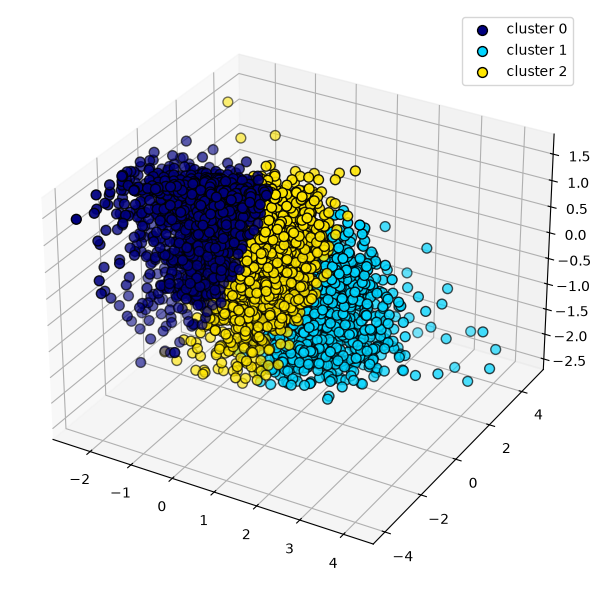

In [50]:
clusterScatter(3, X_features_scaled)


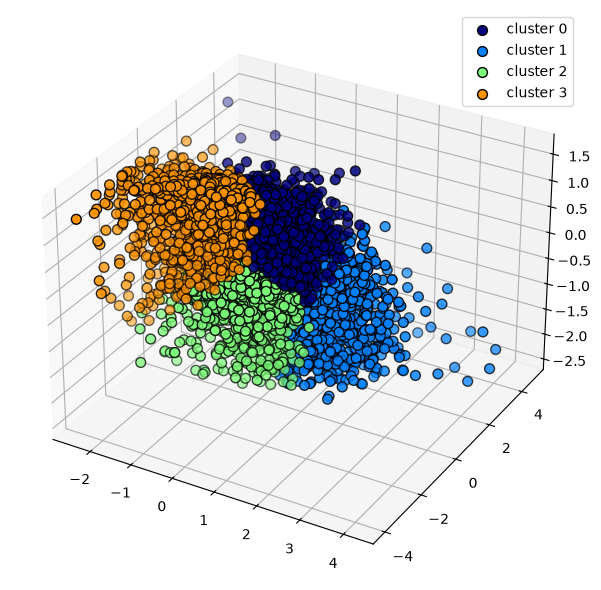

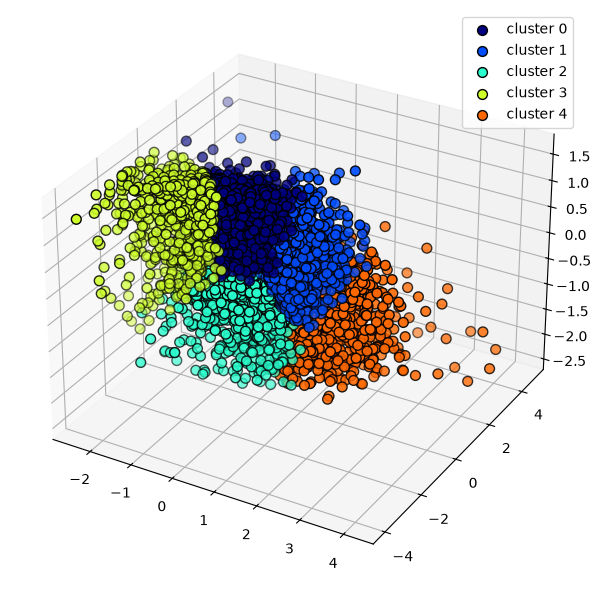

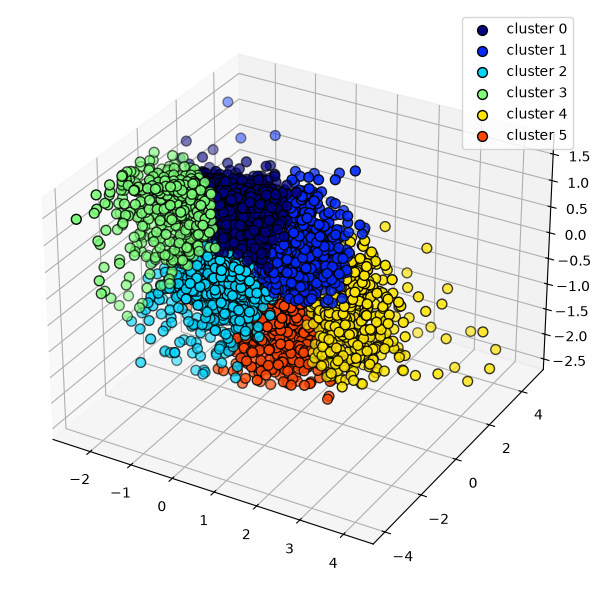

In [51]:
clusterScatter(4, X_features_scaled)
clusterScatter(5, X_features_scaled)
clusterScatter(6, X_features_scaled)